In [7]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Üst dizindeki artifacts klasöründen dosyaları yükleme
artifact_dir = "../artifacts"
print("artifacts klasörü içeriği:", os.listdir(artifact_dir))

train_fe = pd.read_csv(os.path.join(artifact_dir, "train_fe.csv"))
test_fe  = pd.read_csv(os.path.join(artifact_dir, "test_fe.csv"))

with open(os.path.join(artifact_dir, "selected_features.json"), "r") as f:
    selected_features = json.load(f)

# 2. Test seti gerçek RUL değerlerini data klasöründen yükleme
rul_df = pd.read_csv("../data/RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])

# 3. EDA grafiklerinin ortak kullanacağı değişkenleri hazırlama
# (train_clean ayrıca kaydedilmediği için train_fe üzerinden temel sütunları türetiyoruz)
ignore_cols = {"unit", "cycle", "RUL_linear", "RUL_capped125"}
base_feature_cols = [
    c for c in train_fe.columns
    if c not in ignore_cols and not any(suffix in c for suffix in ["_roll_", "_diff"])
]

train_clean = train_fe[["unit", "cycle"] + base_feature_cols + ["RUL_capped125"]].copy()
test_clean  = test_fe[["unit", "cycle"] + base_feature_cols].copy()

print("\nVeriler başarıyla yüklendi!")
print(f"train_fe          : {train_fe.shape}")
print(f"test_fe           : {test_fe.shape}")
print(f"rul_df            : {rul_df.shape}")
print(f"Temel sensör sayısı: {len(base_feature_cols)}")

artifacts klasörü içeriği: ['selected_features.json', 'test_fe.csv', 'train_fe.csv']

Veriler başarıyla yüklendi!
train_fe          : (16561, 72)
test_fe           : (13096, 70)
rul_df            : (100, 1)
Temel sensör sayısı: 17


## 3. Keşifçi Veri Analizi (EDA)

Bu bölümde temizlenmiş ve öznitelikleri türetilmiş veri setleri (`train_fe`, `test_fe`, `rul_df`) üzerinde dağılım, korelasyon, dengesizlik ve görselleştirme analizleri yapılmaktadır. Tüm istatistiksel çıkarımlar veri sızıntısını önlemek amacıyla yalnızca eğitim seti üzerinden gerçekleştirilmiştir.

### 3.1. Yaşam Süresi Analizi (Survival Analysis)

* **Amaç:** Eğitim setindeki motorların arızalanana kadar geçen toplam çalışma döngülerinin (`cycle`) dağılımını ve uç değerlerini belirlemek.

=== EĞİTİM SETİ MOTOR ÖMÜR İSTATİSTİKLERİ ===
Toplam Motor Sayısı : 80
Ortalama Ömür       : 207.01 döngü
Medyan Ömür         : 199.00 döngü
En Kısa Ömür        : 128 döngü (Unit 39)
En Uzun Ömür        : 362 döngü (Unit 69)


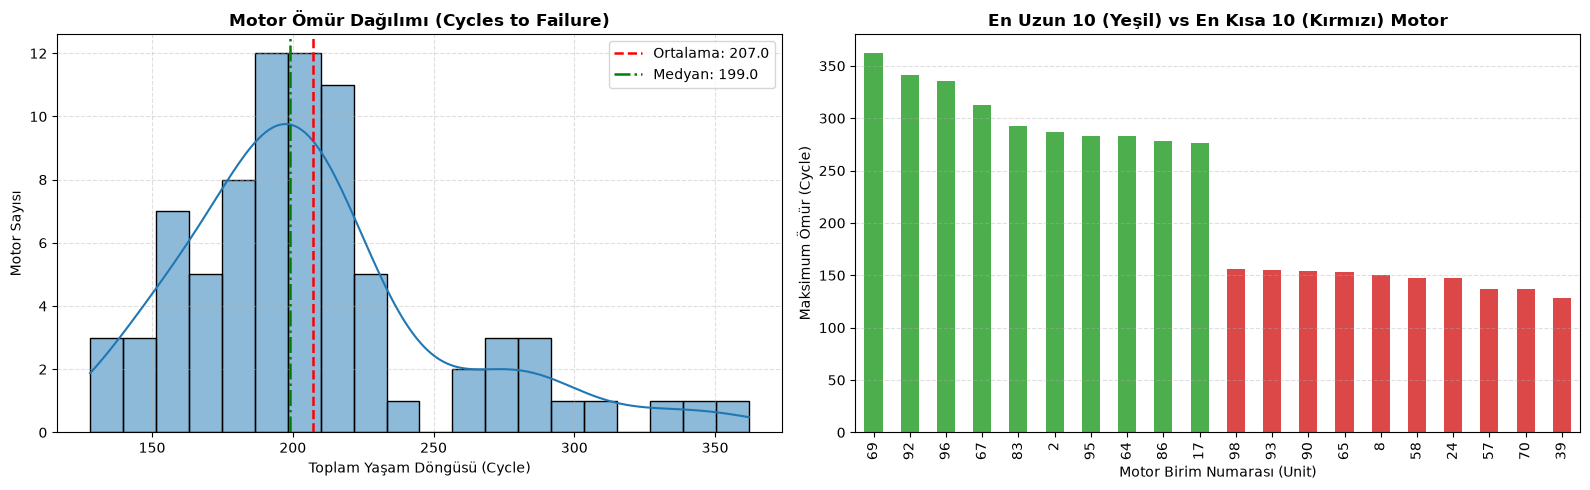

In [8]:
engine_lifespan = train_clean.groupby("unit")["cycle"].max()

print("=== EĞİTİM SETİ MOTOR ÖMÜR İSTATİSTİKLERİ ===")
print(f"Toplam Motor Sayısı : {len(engine_lifespan)}")
print(f"Ortalama Ömür       : {engine_lifespan.mean():.2f} döngü")
print(f"Medyan Ömür         : {engine_lifespan.median():.2f} döngü")
print(f"En Kısa Ömür        : {engine_lifespan.min()} döngü (Unit {engine_lifespan.idxmin()})")
print(f"En Uzun Ömür        : {engine_lifespan.max()} döngü (Unit {engine_lifespan.idxmax()})")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(engine_lifespan, kde=True, color="#1f77b4", bins=20, ax=axes[0])
axes[0].axvline(engine_lifespan.mean(), color="red", linestyle="--", linewidth=1.8, label=f"Ortalama: {engine_lifespan.mean():.1f}")
axes[0].axvline(engine_lifespan.median(), color="green", linestyle="-.", linewidth=1.8, label=f"Medyan: {engine_lifespan.median():.1f}")
axes[0].set_title("Motor Ömür Dağılımı (Cycles to Failure)", fontweight="bold")
axes[0].set_xlabel("Toplam Yaşam Döngüsü (Cycle)")
axes[0].set_ylabel("Motor Sayısı")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

sorted_lifespan = engine_lifespan.sort_values(ascending=False)
extremes = pd.concat([sorted_lifespan.head(10), sorted_lifespan.tail(10)])
colors = ["#2ca02c"] * 10 + ["#d62728"] * 10

extremes.plot(kind="bar", color=colors, alpha=0.85, ax=axes[1])
axes[1].set_title("En Uzun 10 (Yeşil) vs En Kısa 10 (Kırmızı) Motor", fontweight="bold")
axes[1].set_xlabel("Motor Birim Numarası (Unit)")
axes[1].set_ylabel("Maksimum Ömür (Cycle)")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 3.2. Sensör Bozulma Eğilimleri

* **Amaç:** Motorlar arızaya yaklaştıkça (`RUL -> 0`) kritik sensör ölçümlerinin zamana bağlı değişim yönünü (`mean ± std`) incelemek.

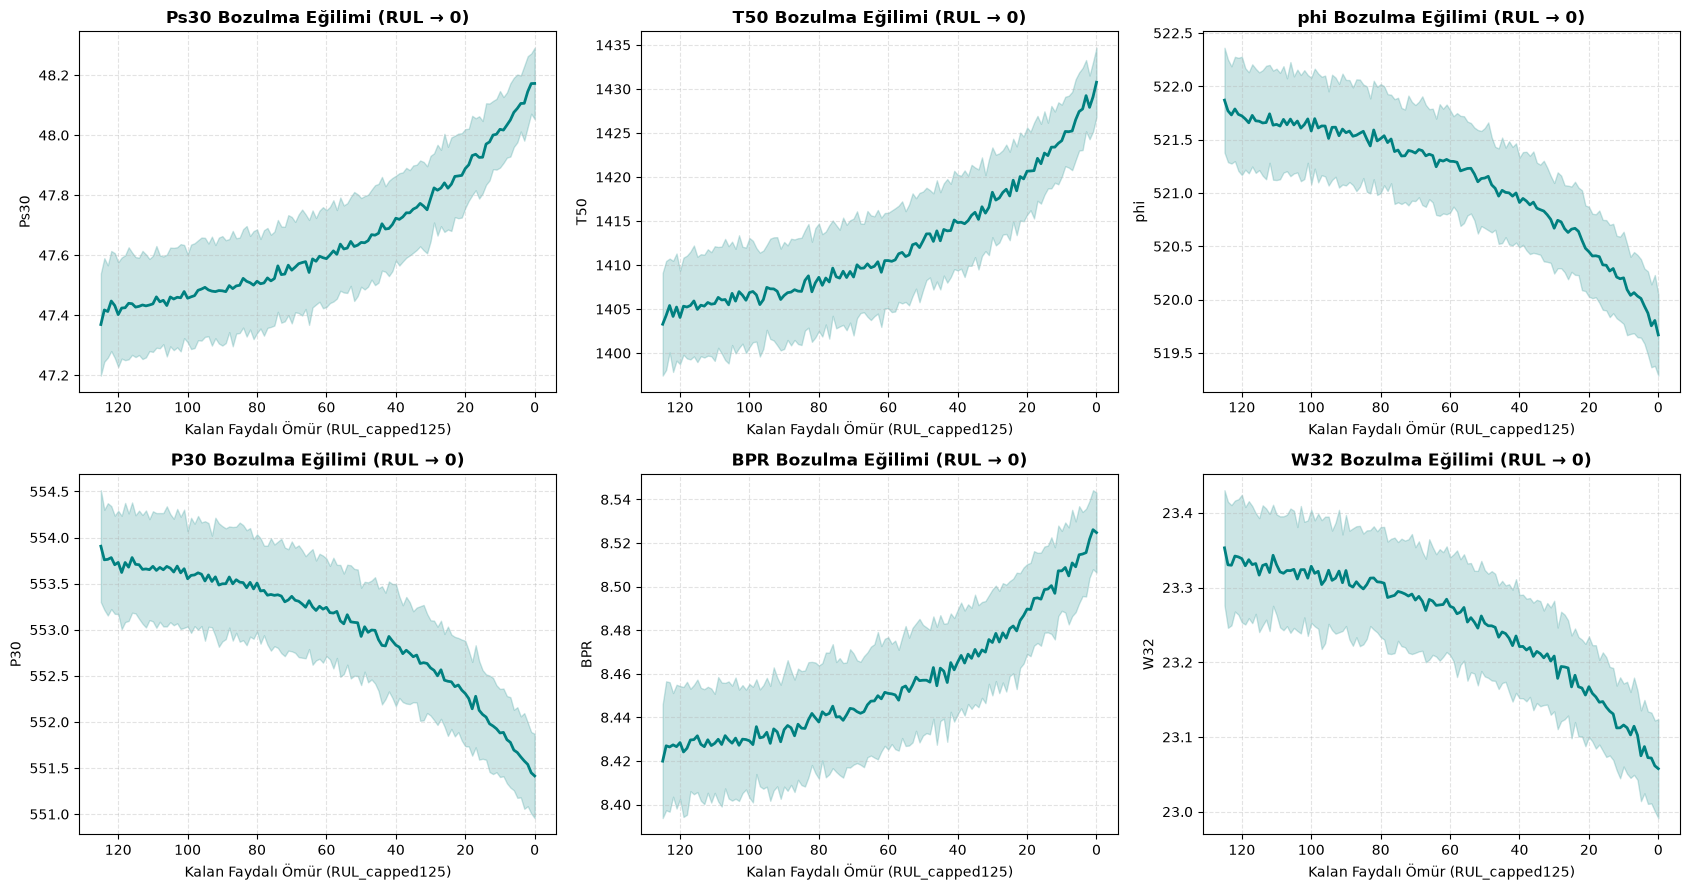

In [9]:
top_sensors = ["Ps30", "T50", "phi", "P30", "BPR", "W32"]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.flatten()

for i, sensor in enumerate(top_sensors):
    sns.lineplot(
        data=train_clean,
        x="RUL_capped125",
        y=sensor,
        ax=axes[i],
        errorbar="sd",
        color="#008080",
        linewidth=2
    )
    axes[i].invert_xaxis()
    axes[i].set_title(f"{sensor} Bozulma Eğilimi (RUL → 0)", fontweight="bold")
    axes[i].set_xlabel("Kalan Faydalı Ömür (RUL_capped125)")
    axes[i].set_ylabel(sensor)
    axes[i].grid(True, linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

### 3.3. Korelasyon ve Öznitelik Katkı Analizi

* **Amaç:** Temel sensörler arasındaki korelasyonu (`heatmap`) incelemek ve türetilen yeni özelliklerin (`roll_mean_10`, `roll_std_10`, `diff`) `RUL_capped125` ile ilişkisini kıyaslamak.

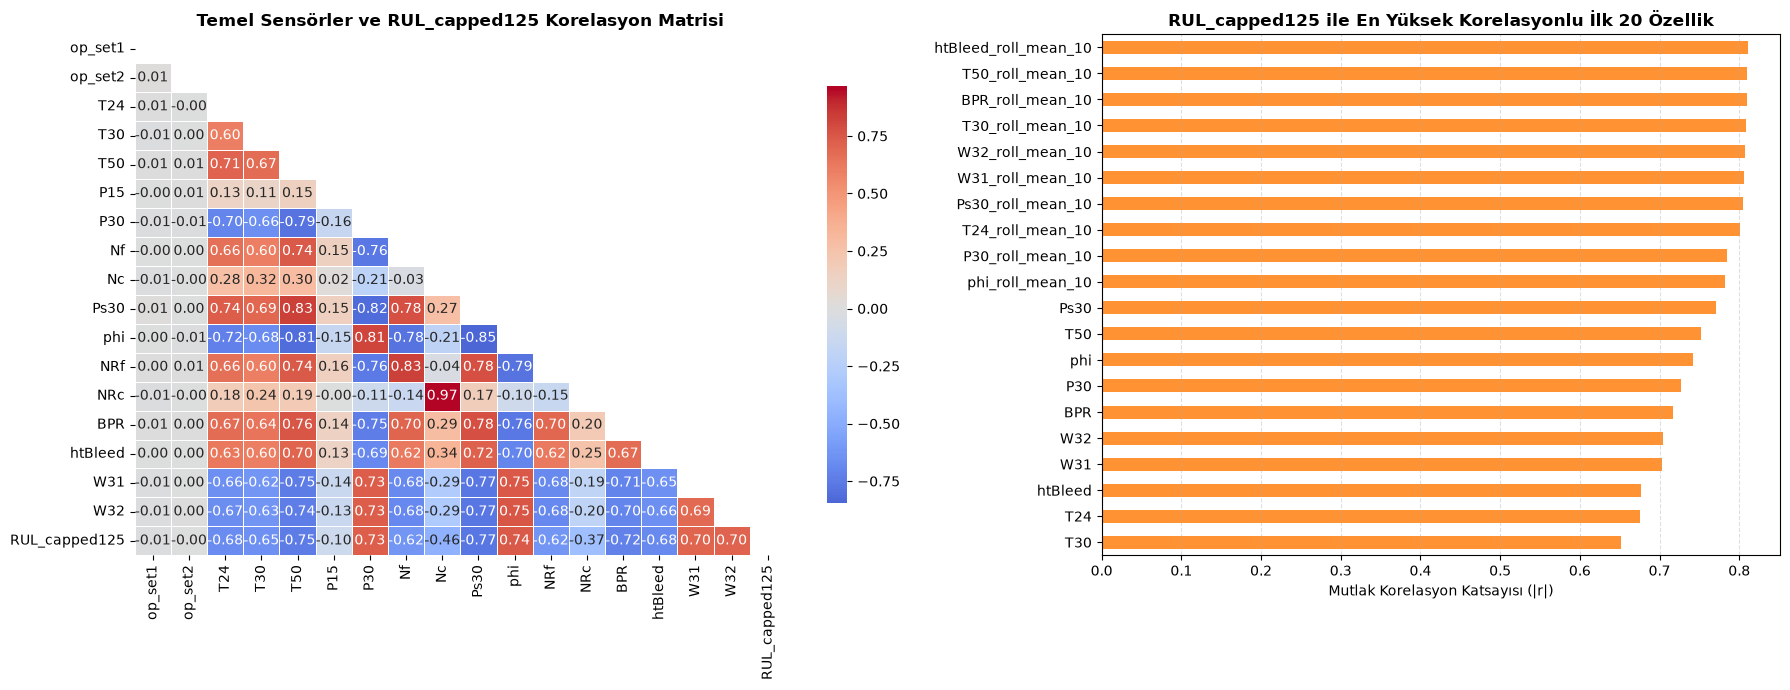

=== EN YÜKSEK KORELASYONLU İLK 15 ÖZELLİK ===
htBleed_roll_mean_10    0.8106
T50_roll_mean_10        0.8097
BPR_roll_mean_10        0.8092
T30_roll_mean_10        0.8081
W32_roll_mean_10        0.8072
W31_roll_mean_10        0.8064
Ps30_roll_mean_10       0.8047
T24_roll_mean_10        0.8012
P30_roll_mean_10        0.7849
phi_roll_mean_10        0.7815
Ps30                    0.7712
T50                     0.7523
phi                     0.7424
P30                     0.7275
BPR                     0.7167
dtype: float64


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1.2, 1]})

corr_matrix = train_clean[base_feature_cols + ["RUL_capped125"]].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=axes[0]
)
axes[0].set_title("Temel Sensörler ve RUL_capped125 Korelasyon Matrisi", fontweight="bold")

fe_cols = [c for c in train_fe.columns if c not in {"unit", "cycle", "RUL_linear", "RUL_capped125"}]
correlations = train_fe[fe_cols].corrwith(train_fe["RUL_capped125"]).abs().sort_values(ascending=False)

correlations.head(20).sort_values().plot(kind="barh", color="#ff7f0e", alpha=0.85, ax=axes[1])
axes[1].set_title("RUL_capped125 ile En Yüksek Korelasyonlu İlk 20 Özellik", fontweight="bold")
axes[1].set_xlabel("Mutlak Korelasyon Katsayısı (|r|)")
axes[1].grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

print("=== EN YÜKSEK KORELASYONLU İLK 15 ÖZELLİK ===")
print(correlations.head(15).round(4))

### 3.4. Test Seti Kapsam ve Kırpılma Analizi

* **Amaç:** Arızadan önce rastgele durdurulan test motorlarının gözlemlenen döngü uzunluklarını ve gerçek kalan ömür (`RUL_FD001`) dağılımlarını incelemek.

=== TEST SETİ İSTATİSTİKLERİ ===
Test Motor Sayısı          : 100
Ortalama Gözlemlenen Döngü : 130.96 (Min: 31, Max: 303)
Ortalama Gerçek RUL        : 75.52 (Min: 7, Max: 145)


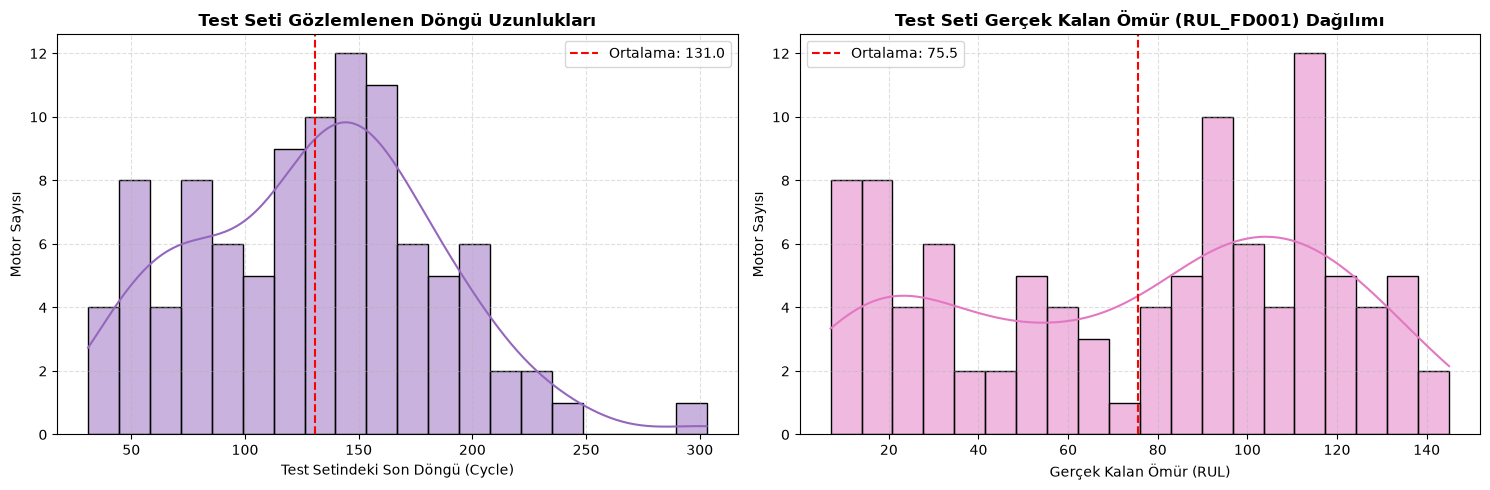

In [11]:
test_max_cycles = test_clean.groupby("unit")["cycle"].max()

print("=== TEST SETİ İSTATİSTİKLERİ ===")
print(f"Test Motor Sayısı          : {len(test_max_cycles)}")
print(f"Ortalama Gözlemlenen Döngü : {test_max_cycles.mean():.2f} (Min: {test_max_cycles.min()}, Max: {test_max_cycles.max()})")
print(f"Ortalama Gerçek RUL        : {rul_df['RUL'].mean():.2f} (Min: {rul_df['RUL'].min()}, Max: {rul_df['RUL'].max()})")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(test_max_cycles, bins=20, kde=True, color="#9467bd", ax=axes[0])
axes[0].axvline(test_max_cycles.mean(), color="red", linestyle="--", label=f"Ortalama: {test_max_cycles.mean():.1f}")
axes[0].set_title("Test Seti Gözlemlenen Döngü Uzunlukları", fontweight="bold")
axes[0].set_xlabel("Test Setindeki Son Döngü (Cycle)")
axes[0].set_ylabel("Motor Sayısı")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

sns.histplot(rul_df["RUL"], bins=20, kde=True, color="#e377c2", ax=axes[1])
axes[1].axvline(rul_df["RUL"].mean(), color="red", linestyle="--", label=f"Ortalama: {rul_df['RUL'].mean():.1f}")
axes[1].set_title("Test Seti Gerçek Kalan Ömür (RUL_FD001) Dağılımı", fontweight="bold")
axes[1].set_xlabel("Gerçek Kalan Ömür (RUL)")
axes[1].set_ylabel("Motor Sayısı")
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend()

plt.tight_layout()
plt.show()

### 3.5. Sınıf Dengesizliği, SMOTE ve Saçılım (Scatter) Analizi

* **Amaç:** Hedef değişkenin (`RUL_capped125`) dağılımını incelemek, sağlık sınıfları (`Kritik <= 30`, `Uyarı <= 80`, `Sağlıklı > 80`) bazında dengesizliği analiz ederek yalnızca eğitim setine `SMOTE` uygulamak ve kritik sensörler arasındaki ilişkiyi (`scatter plot`) görselleştirmek.

=== SMOTE ÖNCESİ SINIF DAĞILIMI ===
Kritik (RUL<=30): 2480 örnek (%15.0)
Uyarı (30<RUL<=80): 4000 örnek (%24.2)
Sağlıklı (RUL>80): 10081 örnek (%60.9)

=== SMOTE SONRASI SINIF DAĞILIMI ===
Kritik (RUL<=30): 10081 örnek (%33.3)
Uyarı (30<RUL<=80): 10081 örnek (%33.3)
Sağlıklı (RUL>80): 10081 örnek (%33.3)


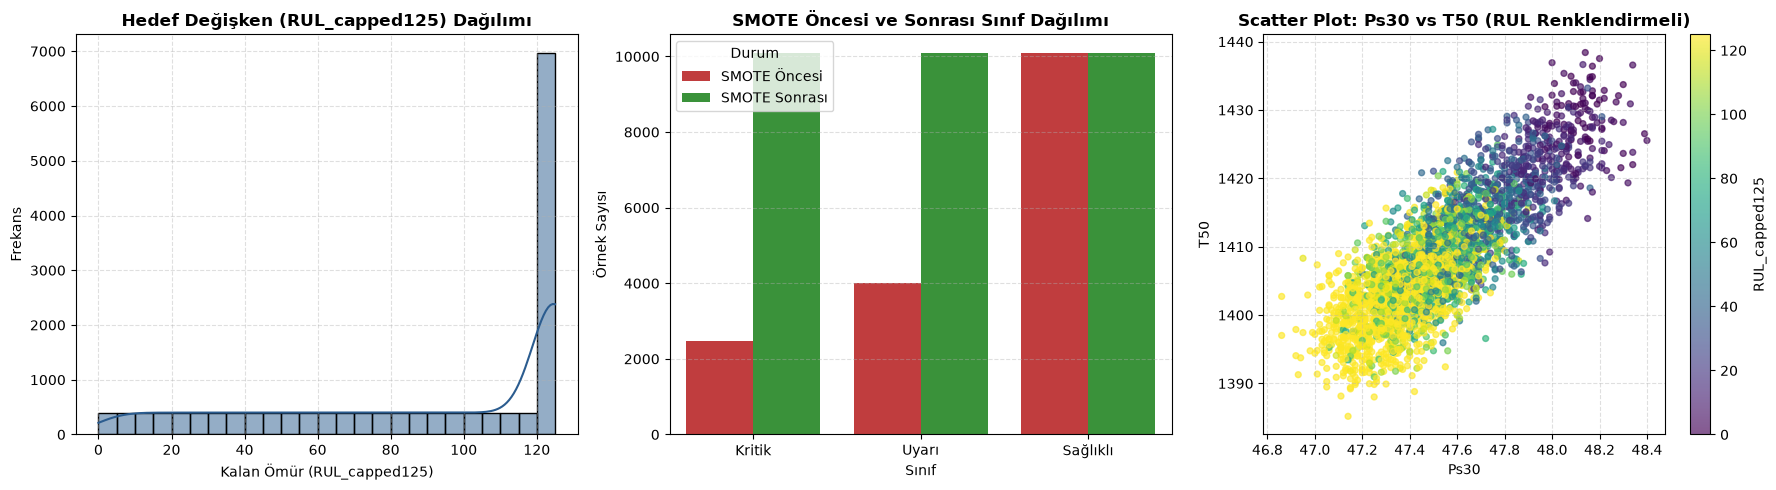

In [13]:
from imblearn.over_sampling import SMOTE

def categorize_rul(rul):
    if rul <= 30:
        return 0  # Kritik
    elif rul <= 80:
        return 1  # Uyarı
    else:
        return 2  # Sağlıklı

y_train_class = train_fe["RUL_capped125"].apply(categorize_rul)
X_train_smote_input = train_fe[fe_cols]

class_names = {0: "Kritik (RUL<=30)", 1: "Uyarı (30<RUL<=80)", 2: "Sağlıklı (RUL>80)"}
before_counts = y_train_class.value_counts().sort_index()

print("=== SMOTE ÖNCESİ SINIF DAĞILIMI ===")
for k, v in before_counts.items():
    print(f"{class_names[k]}: {v} örnek (%{v/len(y_train_class)*100:.1f})")

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_smote_input, y_train_class)
after_counts = pd.Series(y_train_balanced).value_counts().sort_index()

print("\n=== SMOTE SONRASI SINIF DAĞILIMI ===")
for k, v in after_counts.items():
    print(f"{class_names[k]}: {v} örnek (%{v/len(y_train_balanced)*100:.1f})")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(train_fe["RUL_capped125"], bins=25, kde=True, color="#2b5c8f", ax=axes[0])
axes[0].set_title("Hedef Değişken (RUL_capped125) Dağılımı", fontweight="bold")
axes[0].set_xlabel("Kalan Ömür (RUL_capped125)")
axes[0].set_ylabel("Frekans")
axes[0].grid(True, linestyle="--", alpha=0.4)

df_smote_compare = pd.DataFrame({
    "Sınıf": ["Kritik", "Uyarı", "Sağlıklı"],
    "SMOTE Öncesi": before_counts.values,
    "SMOTE Sonrası": after_counts.values
}).melt(id_vars="Sınıf", var_name="Durum", value_name="Örnek Sayısı")

sns.barplot(data=df_smote_compare, x="Sınıf", y="Örnek Sayısı", hue="Durum", palette=["#d62728", "#2ca02c"], ax=axes[1])
axes[1].set_title("SMOTE Öncesi ve Sonrası Sınıf Dağılımı", fontweight="bold")
axes[1].set_ylabel("Örnek Sayısı")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

sample_df = train_clean.sample(n=min(3000, len(train_clean)), random_state=42)
scatter = axes[2].scatter(sample_df["Ps30"], sample_df["T50"], c=sample_df["RUL_capped125"], cmap="viridis", alpha=0.65, s=18)
plt.colorbar(scatter, ax=axes[2], label="RUL_capped125")
axes[2].set_title("Scatter Plot: Ps30 vs T50 (RUL Renklendirmeli)", fontweight="bold")
axes[2].set_xlabel("Ps30")
axes[2].set_ylabel("T50")
axes[2].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 3.6. Sağlık Durumu Ayrışması (KDE) ve 2B PCA Bozulma Yörüngesi

* **Amaç:** Motorun ilk 20 döngüsü (sağlıklı) ile son 20 döngüsü (arızaya yakın) arasındaki sensör dağılım ayrışmasını (`KDE`) incelemek ve tüm öznitelik uzayını (`train_fe`) `PCA` ile 2 boyuta indirgeyerek bozulma yörüngesini görselleştirmek.

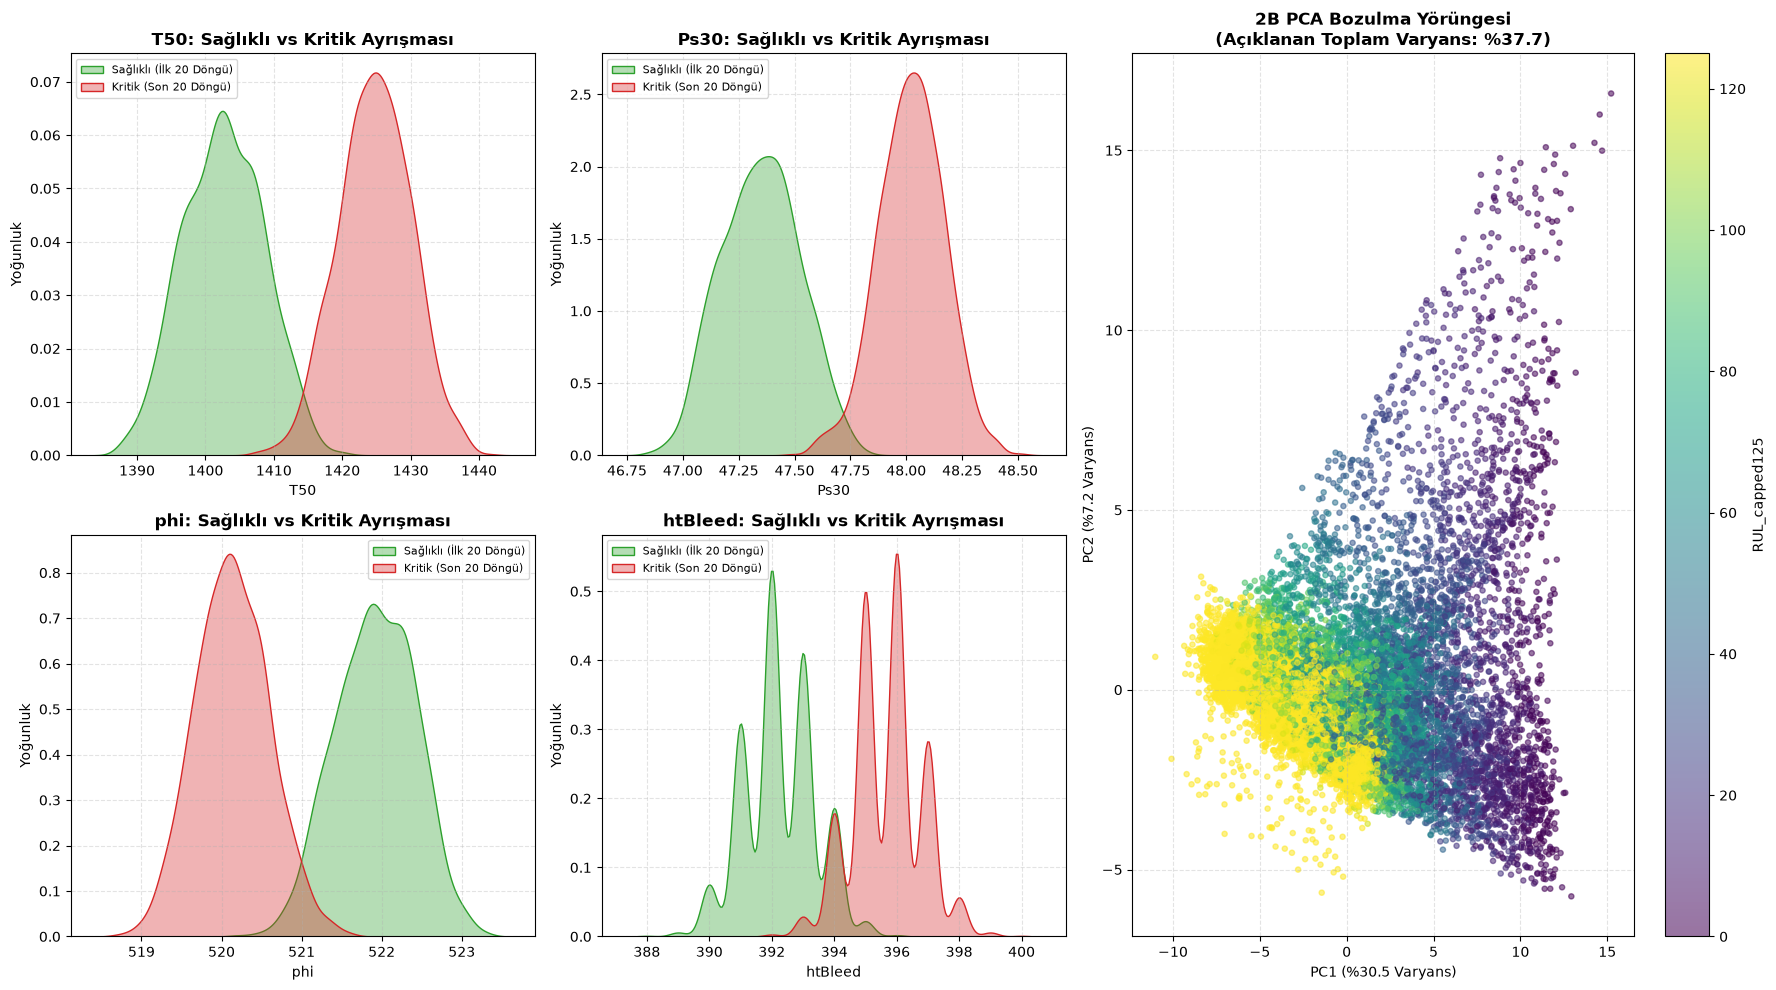

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.35])

# 1. Sol 4 Grafik: Sağlıklı (İlk 20 Döngü) vs Arızaya Yakın (Son 20 Döngü) KDE Ayrışması
early_life = train_clean[train_clean["cycle"] <= 20]
late_life  = train_clean[train_clean["RUL_capped125"] <= 20]

sensors_to_compare = ["T50", "Ps30", "phi", "htBleed"]
kde_positions = [(0, 0), (0, 1), (1, 0), (1, 1)]

for idx, sensor in enumerate(sensors_to_compare):
    ax = fig.add_subplot(gs[kde_positions[idx]])
    sns.kdeplot(early_life[sensor], fill=True, color="#2ca02c", label="Sağlıklı (İlk 20 Döngü)", ax=ax, alpha=0.35)
    sns.kdeplot(late_life[sensor], fill=True, color="#d62728", label="Kritik (Son 20 Döngü)", ax=ax, alpha=0.35)
    ax.set_title(f"{sensor}: Sağlıklı vs Kritik Ayrışması", fontweight="bold")
    ax.set_xlabel(sensor)
    ax.set_ylabel("Yoğunluk")
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(fontsize=8)

# 2. Sağ Büyük Grafik: Tüm Özniteliklerin 2B PCA Bozulma Yörüngesi
ax_pca = fig.add_subplot(gs[:, 2])

X_scaled = StandardScaler().fit_transform(train_fe[fe_cols])
pca = PCA(n_components=2, random_state=42)
pca_components = pca.fit_transform(X_scaled)

sc = ax_pca.scatter(
    pca_components[:, 0],
    pca_components[:, 1],
    c=train_fe["RUL_capped125"],
    cmap="viridis",
    alpha=0.55,
    s=14
)
plt.colorbar(sc, ax=ax_pca, label="RUL_capped125")
ax_pca.set_title(
    f"2B PCA Bozulma Yörüngesi\n(Açıklanan Toplam Varyans: %{pca.explained_variance_ratio_.sum()*100:.1f})",
    fontweight="bold"
)
ax_pca.set_xlabel(f"PC1 (%{pca.explained_variance_ratio_[0]*100:.1f} Varyans)")
ax_pca.set_ylabel(f"PC2 (%{pca.explained_variance_ratio_[1]*100:.1f} Varyans)")
ax_pca.grid(True, linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()